# BÀI THỰC HÀNH: PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EXPLORATORY DATA ANALYSIS - EDA)
**Trường Đại học Sài Gòn**
---
Notebook này được cấu trúc hoàn chỉnh theo các yêu cầu của tài liệu thực hành:
1. **Phần A: Ôn tập Lý thuyết & Câu hỏi thảo luận**
2. **Phần B: Code các Bài tập mẫu (COVID-19, Marketing Campaign, House Prices, Penguins)**
3. **Phần C: Thực hành trên các tập dữ liệu được cung cấp (`winequality-red.csv`, `Customer_Behaviour.csv`, `Online Retail.xlsx`)**
4. **Phần D: Hướng dẫn các công cụ Automated EDA (`ydata_profiling`, `dtale`, `sweetviz`, `autoviz`)**



---
## PHẦN A: ÔN TẬP LÝ THUYẾT VÀ LỜI GIẢI CHI TIẾT

### 1.1. Thống kê mô tả (Descriptive Statistics)
1. **Thống kê mô tả là gì? Khác gì với thống kê suy luận (Inferential Statistics)?**
   - *Thống kê mô tả (Descriptive Statistics):* Tập hợp các phương pháp tóm tắt, trình bày và mô tả các đặc tính chính của một tập dữ liệu hiện có (thông qua bảng, biểu đồ, trung bình, độ lệch chuẩn,...) mà không đưa ra kết luận vượt quá dữ liệu đó.
   - *Thống kê suy luận (Inferential Statistics):* Sử dụng dữ liệu từ một mẫu (sample) để đưa ra các dự đoán, suy luận hoặc kiểm định giả thuyết về toàn bộ tổng thể (population).

2. **Các thước đo thống kê mô tả chính được sử dụng để làm gì? Khi nào dùng Trung vị (Median) thay vì Trung bình (Mean)?**
   - *Ý nghĩa:* Đo lường xu hướng tập trung (Mean, Median, Mode) và độ phân tán (Variance, Standard Deviation, IQR, Range) của dữ liệu.
   - *Khi nào dùng Median:* Khi dữ liệu có phân bố lệch (skewed) hoặc chứa nhiều giá trị ngoại lai (outliers) cực đoan (ví dụ: thu nhập, giá nhà), vì Trung vị không bị ảnh hưởng bởi giá trị bất thường như Trung bình.

3. **Cách xác định phân bố của dữ liệu & các loại phân bố phổ biến:**
   - *Cách xác định:* Dùng biểu đồ Histogram, KDE plot, Boxplot hoặc các kiểm định thống kê (Shapiro-Wilk), chỉ số Skewness (độ lệch) và Kurtosis (độ nhọn).
   - *Các loại phân bố phổ biến:* Phân bố chuẩn (Normal Distribution - đối xứng), Phân bố lệch phải (Right-skewed), Phân bố lệch trái (Left-skewed), Phân bố đồng nhất (Uniform).

4. **Ý nghĩa của Độ lệch chuẩn (Std Dev) và Phạm vi (Range):**
   - *Phạm vi (Range):* Khoảng cách giữa Max và Min ($Max - Min$), thể hiện độ mở rộng tổng thể của dữ liệu.
   - *Độ lệch chuẩn (Std Dev):* Mức độ biến động trung bình của các điểm dữ liệu so với giá trị trung bình. Std Dev càng lớn thì dữ liệu càng phân tán.

5. **Sự khác biệt giữa Q1, Q2, Q3 trong Boxplot:**
   - *Q1 (25th Percentile):* 25% dữ liệu nhỏ hơn giá trị này.
   - *Q2 (50th Percentile / Median):* Trung vị, chia dữ liệu thành 2 phần bằng nhau.
   - *Q3 (75th Percentile):* 75% dữ liệu nhỏ hơn giá trị này.
   - Khoảng tứ phân vị $IQR = Q3 - Q1$.

6. **Xử lý giá trị thiếu (Missing values) trước khi tính thống kê mô tả:**
   - Loại bỏ các dòng/cột thiếu (nếu tỉ lệ thiếu $<5\%$).
   - Điền giá trị (Imputation): Dùng Mean (cho phân bố chuẩn), Median (cho phân bố lệch/có outlier), Mode (cho biến phân loại), hoặc thuật toán KNN Imputer.

7. **Cách đọc và diễn giải Histogram & Boxplot:**
   - *Histogram:* Trục hoành biểu diễn các khoảng giá trị (bins), trục tung biểu diễn số lượng bản ghi (count). Cho biết hình dáng phân bố dữ liệu.
   - *Boxplot:* Cho biết vạch Trung vị (Q2), khoảng IQR (Q1 đến Q3), các giá trị nằm ngoài vạch $1.5 \times IQR$ được xem là giá trị ngoại lai (outliers).

8. **Xử lý Outliers trước khi thực hiện thống kê mô tả:**
   - Phát hiện bằng Z-score ($|Z| > 3$) hoặc IQR.
   - Xử lý: Cắt ngưỡng (Winsorization), loại bỏ (nếu là lỗi nhập liệu), hoặc dùng các chỉ số chắc chắn (Robust statistics) như Median và IQR.

---

### 1.2. Xử lý và Trực quan hóa dữ liệu (Data Visualization)
1. **Vai trò của Trực quan hóa dữ liệu:** Giúp phát hiện nhanh chóng các mẫu (patterns), xu hướng (trends), mối tương quan và giá trị bất thường trong dữ liệu mà các số liệu đơn thuần khó thể hiện.
2. **Các loại biểu đồ phổ biến:**
   - *Histogram:* Xem phân bố của 1 biến liên tục.
   - *Scatter plot:* Xem mối tương quan giữa 2 biến liên tục.
   - *Boxplot / Violin plot:* So sánh phân bố biến số theo các nhóm phân loại, phát hiện outlier.
   - *Bar chart / Countplot:* So sánh số lượng/tần suất giữa các nhóm phân loại.
   - *Heatmap:* Biểu diễn ma trận tương quan giữa nhiều biến số.
3. **Phân biệt Matplotlib, Seaborn và Plotly:**
   - *Matplotlib:* Thư viện nền tảng, cho phép tùy biến chi tiết, tạo biểu đồ tĩnh.
   - *Seaborn:* Xây dựng trên Matplotlib, đẹp hơn, tích hợp sẵn các biểu đồ thống kê nâng cao.
   - *Plotly:* Tạo biểu đồ tương tác (interactive), hỗ trợ zoom, hover, xuất ra HTML.

---

### 1.3. Phân tích đơn biến và hai biến (Univariate & Bivariate Analysis)
1. **Univariate vs Bivariate Analysis:**
   - *Univariate:* Phân tích độc lập từng biến để hiểu phân bố và đặc tính của biến đó.
   - *Bivariate:* Phân tích mối quan hệ và sự ảnh hưởng lẫn nhau giữa 2 biến số.
2. **Correlation vs Covariance:**
   - *Covariance (Hiệp biến):* Đo chiều hướng biến thiên cùng nhau, phụ thuộc vào đơn vị đo.
   - *Correlation (Hệ số tương quan):* Đã chuẩn hóa về khoảng $[-1, 1]$, đo độ mạnh yếu của mối quan hệ tuyến tính, không phụ thuộc đơn vị đo.



---
## PHẦN B: BÀI LÀM MẪU TRONG TÀI LIỆU (COVID-19, MARKETING, HOUSE PRICES, PENGUINS)



In [12]:
# Import các thư viện xử lý và trực quan hóa dữ liệu
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Tạo thư mục img nằm ngoài thư mục Code (song song với Code và data)
os.makedirs('../img', exist_ok=True)

# Cấu hình giao diện đồ họa
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
print("Thư viện đã được nạp thành công và thư mục img đã sẵn sàng!")

Thư viện đã được nạp thành công và thư mục img đã sẵn sàng!


In [7]:
# 1. Bài làm mẫu: Thống kê mô tả tập dữ liệu COVID-19 (Minh họa)
np.random.seed(42)
covid_data = pd.DataFrame({
    'iso_code': ['VNM']*100,
    'continent': ['Asia']*100,
    'location': ['Vietnam']*100,
    'date': pd.date_range(start="2020-01-01", periods=100),
    'total_cases': np.cumsum(np.random.randint(10, 500, size=100)),
    'new_cases': np.random.randint(5, 100, size=100)
})

# Tính toán các chỉ số thống kê mô tả
print("=== THỐNG KÊ MÔ TẢ DỮ LIỆU COVID-19 ===")
print("Mean (Trung bình):", np.mean(covid_data["new_cases"]))
print("Median (Trung vị):", np.median(covid_data["new_cases"]))
print("Mode (Yếu tố):", stats.mode(covid_data["new_cases"], keepdims=True).mode[0])
print("Variance (Phương sai):", np.var(covid_data["new_cases"]))
print("Standard Deviation (Độ lệch chuẩn):", np.std(covid_data["new_cases"]))
print("Min / Max:", np.min(covid_data["new_cases"]), "/", np.max(covid_data["new_cases"]))
print("60th Percentile:", np.percentile(covid_data["new_cases"], 60))
print("IQR (Khoảng tứ phân vị):", stats.iqr(covid_data["new_cases"]))



=== THỐNG KÊ MÔ TẢ DỮ LIỆU COVID-19 ===
Mean (Trung bình): 51.95
Median (Trung vị): 48.5
Mode (Yếu tố): 19
Variance (Phương sai): 812.2474999999998
Standard Deviation (Độ lệch chuẩn): 28.499956140317124
Min / Max: 5 / 99
60th Percentile: 63.4
IQR (Khoảng tứ phân vị): 46.75


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_22376\2569076624.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=housing_data, x='Zip', y='Price', ax=ax[0], palette='Blues_r')
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_22376\2569076624.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=housing_data, x='Zip', y='PriceperSqm', ax=ax[1], palette='Oranges_r')


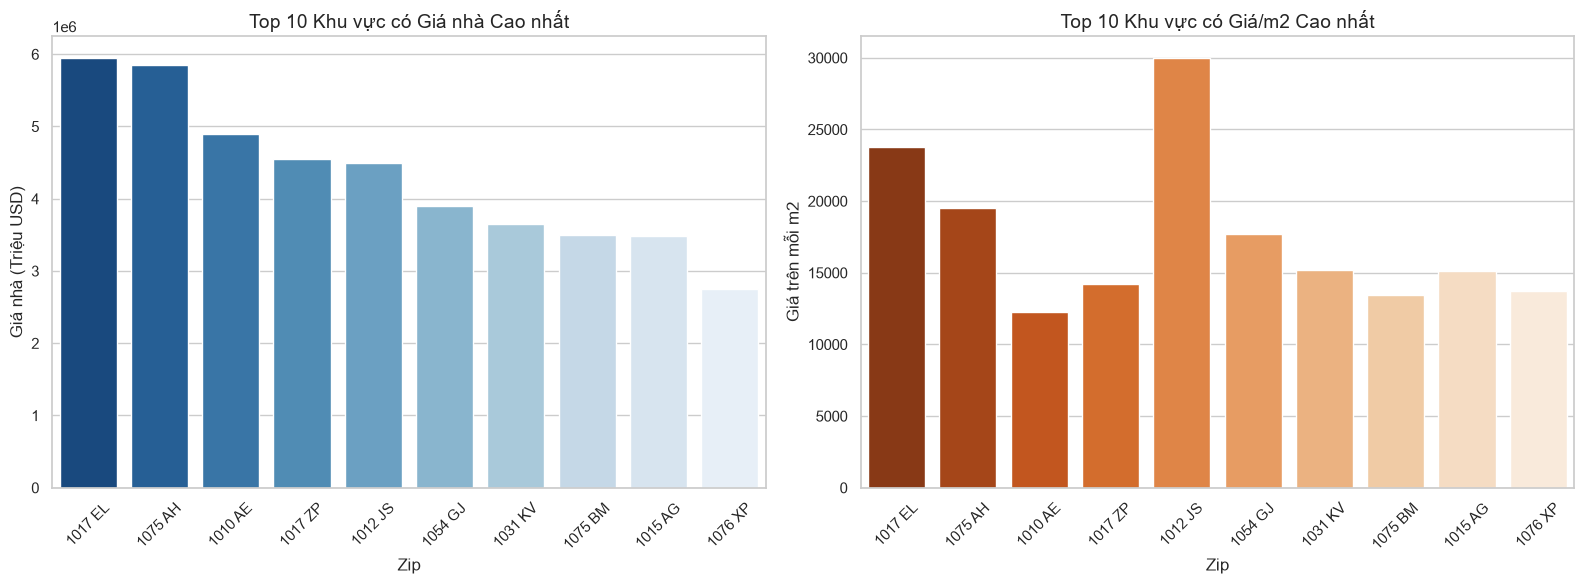

In [13]:
# 2. Bài làm mẫu: Trực quan hóa Dữ liệu Giá nhà (Matplotlib & Seaborn)
housing_data = pd.DataFrame({
    'Zip': ['1017 EL', '1075 AH', '1010 AE', '1017 ZP', '1012 JS', '1054 GJ', '1031 KV', '1075 BM', '1015 AG', '1076 XP'],
    'Price': [5.95e6, 5.85e6, 4.90e6, 4.55e6, 4.50e6, 3.90e6, 3.65e6, 3.50e6, 3.48e6, 2.75e6],
    'Area': [250, 300, 400, 320, 150, 220, 240, 260, 230, 200]
})
housing_data['PriceperSqm'] = housing_data['Price'] / housing_data['Area']

# Vẽ biểu đồ kết hợp (Subplots)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=housing_data, x='Zip', y='Price', ax=ax[0], palette='Blues_r')
ax[0].set_title('Top 10 Khu vực có Giá nhà Cao nhất', fontsize=14)
ax[0].set_ylabel('Giá nhà (Triệu USD)')
ax[0].tick_params(axis='x', rotation=45)

sns.barplot(data=housing_data, x='Zip', y='PriceperSqm', ax=ax[1], palette='Oranges_r')
ax[1].set_title('Top 10 Khu vực có Giá/m2 Cao nhất', fontsize=14)
ax[1].set_ylabel('Giá trên mỗi m2')
ax[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('../img/housing_prices.png', dpi=300)
plt.show()

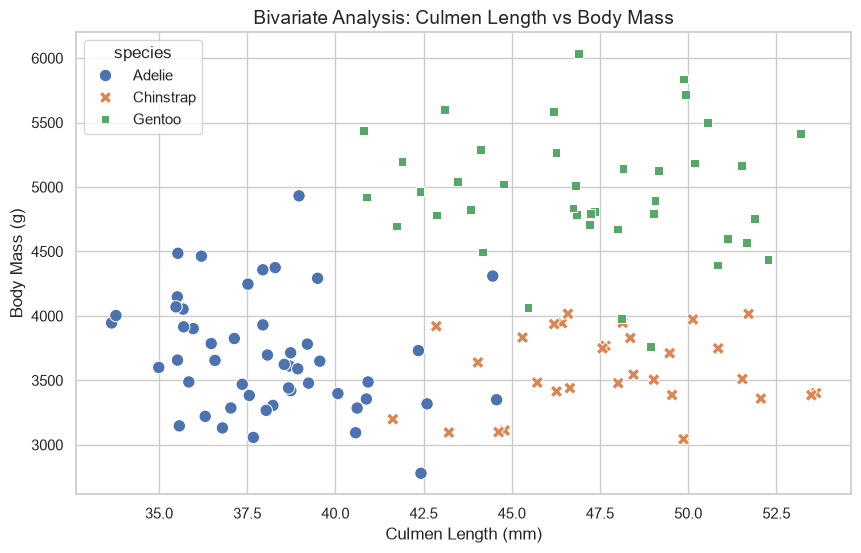

In [14]:
# 3. Bài làm mẫu: Phân tích Đơn biến & Hai biến trên Dữ liệu Chim cánh cụt (Penguins)
penguins_data = pd.DataFrame({
    'species': ['Adelie']*50 + ['Chinstrap']*30 + ['Gentoo']*40,
    'culmen_length_mm': np.concatenate([np.random.normal(38, 3, 50), np.random.normal(48, 3, 30), np.random.normal(47, 3, 40)]),
    'body_mass_g': np.concatenate([np.random.normal(3700, 400, 50), np.random.normal(3730, 380, 30), np.random.normal(5000, 500, 40)])
})

# Bivariate Scatterplot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=penguins_data, x='culmen_length_mm', y='body_mass_g', hue='species', style='species', s=80)
plt.title('Bivariate Analysis: Culmen Length vs Body Mass', fontsize=14)
plt.xlabel('Culmen Length (mm)')
plt.ylabel('Body Mass (g)')
plt.savefig('../img/penguins_analysis.png', dpi=300)
plt.show()

---
## PHẦN C: THỰC HÀNH CHI TIẾT TRÊN CÁC TẬP DỮ LIỆU ĐÃ TẢI

### 3.1. Bài tập thực hành 1: Phân tích Chất lượng Rượu Đỏ (`winequality-red.csv`)



In [15]:
# 1. Nạp và kiểm tra dữ liệu Wine Quality
df_wine = pd.read_csv("../data/WineQuaility-Red/winequality-red.csv")

print("=== 5 DÒNG ĐẦU DỮ LIỆU WINE QUALITY ===")
display(df_wine.head())

print("\n=== TỔNG QUAN VỀ DỮ LIỆU ===")
df_wine.info()

print("\n=== BẢNG THỐNG KÊ MÔ TẢ CHI TIẾT ===")
display(df_wine.describe().T)

print("\n=== KIỂM TRA GIÁ TRỊ THIẾU ===")
print(df_wine.isnull().sum())

=== 5 DÒNG ĐẦU DỮ LIỆU WINE QUALITY ===


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5



=== TỔNG QUAN VỀ DỮ LIỆU ===
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

=== BẢNG THỐNG KÊ MÔ TẢ CHI TIẾT ===


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000



=== KIỂM TRA GIÁ TRỊ THIẾU ===
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_22376\3649453417.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_wine, x='quality', ax=axes[0, 0], palette='viridis')
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_22376\3649453417.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_wine, x='quality', y='alcohol', ax=axes[1, 0], palette='magma')


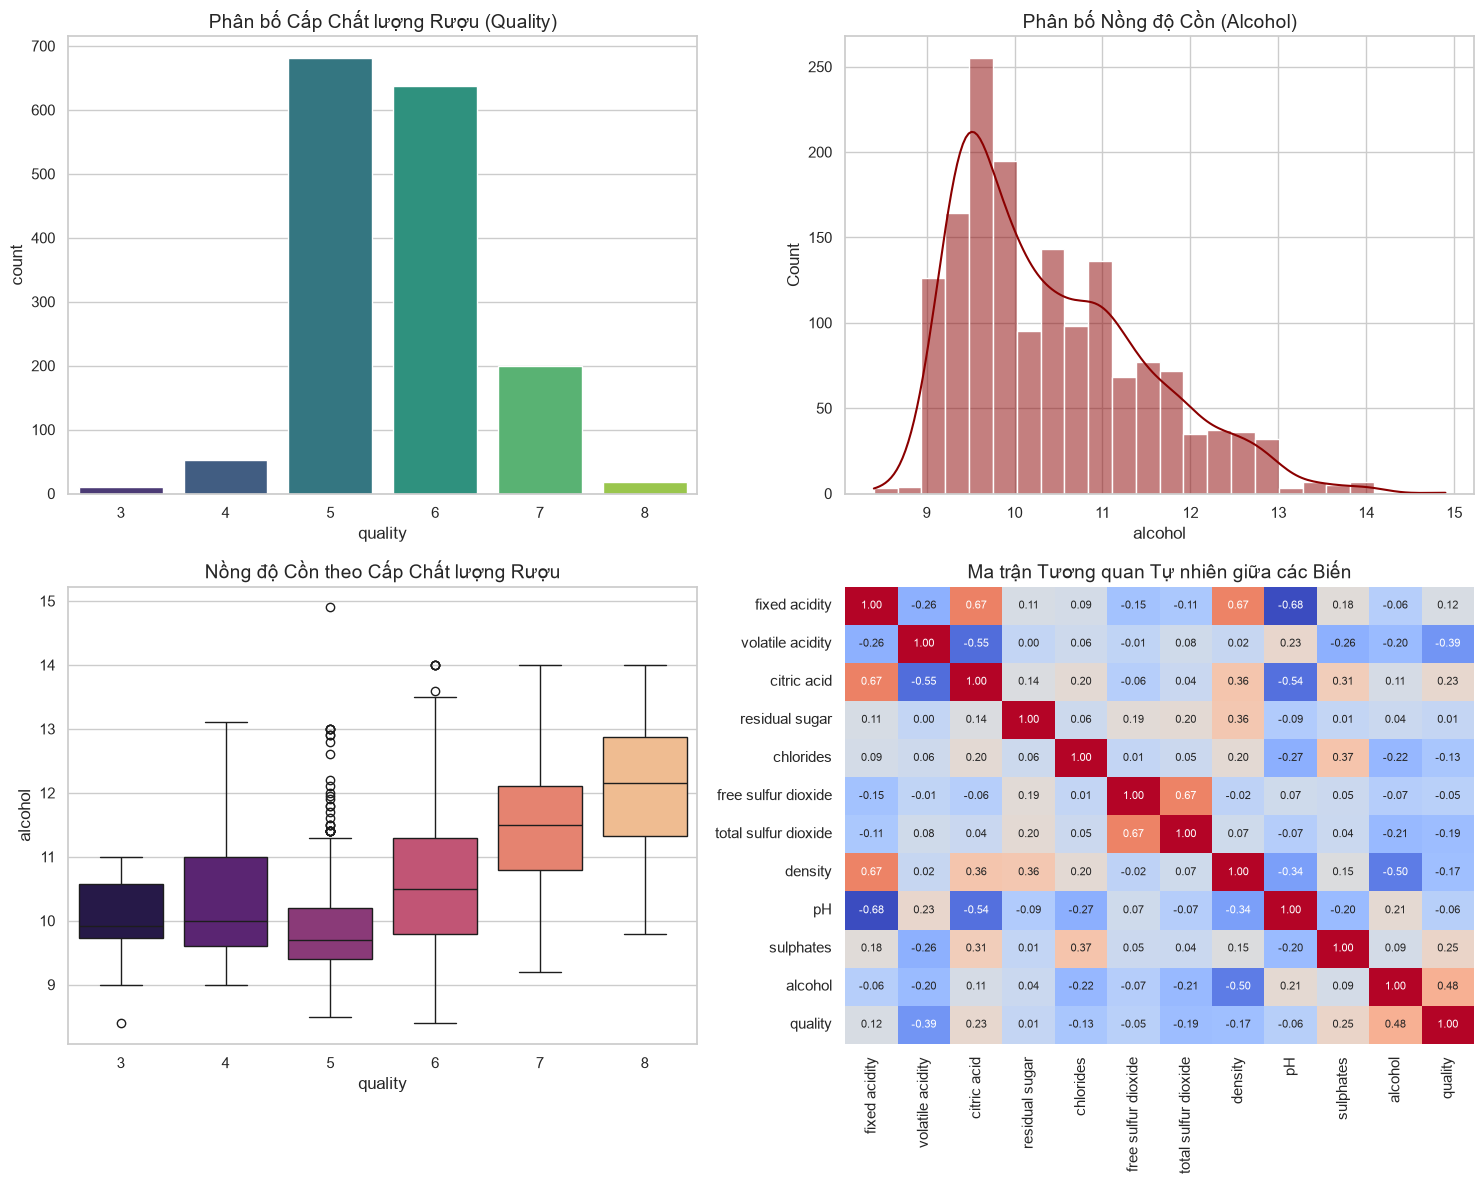

In [16]:
# 2. Trực quan hóa và Phân tích Dữ liệu Wine Quality
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Biểu đồ 1: Phân bố Chất lượng rượu (Quality)
sns.countplot(data=df_wine, x='quality', ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Phân bố Cấp Chất lượng Rượu (Quality)', fontsize=14)

# Biểu đồ 2: Phân bố Nồng độ Cồn (Alcohol)
sns.histplot(data=df_wine, x='alcohol', kde=True, ax=axes[0, 1], color='darkred')
axes[0, 1].set_title('Phân bố Nồng độ Cồn (Alcohol)', fontsize=14)

# Biểu đồ 3: Mối quan hệ giữa Alcohol và Quality (Boxplot)
sns.boxplot(data=df_wine, x='quality', y='alcohol', ax=axes[1, 0], palette='magma')
axes[1, 0].set_title('Nồng độ Cồn theo Cấp Chất lượng Rượu', fontsize=14)

# Biểu đồ 4: Heatmap Ma trận tương quan
sns.heatmap(df_wine.corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1, 1], cbar=False, annot_kws={"size": 8})
axes[1, 1].set_title('Ma trận Tương quan Tự nhiên giữa các Biến', fontsize=14)

plt.tight_layout()
plt.savefig('../img/wine_quality_analysis.png', dpi=300)
plt.show()

### 3.2. Bài tập thực hành 2: Phân tích Hành vi Khách hàng (`Customer_Behaviour.csv`)


In [ ]:
# 1. Nạp và khám phá dữ liệu Hành vi Khách hàng
df_cust = pd.read_csv("../data/Customer Behaviour Prediction( Naive Bayes)/Customer_Behaviour.csv")

print("=== 5 DÒNG ĐẦU DỮ LIỆU KHÁCH HÀNG ===")
display(df_cust.head())

print("\n=== BẢNG THỐNG KÊ MÔ TẢ ===")
display(df_cust.describe().T)

print("\n=== KIỂM TRA DỮ LIỆU THIẾU ===")
print(df_cust.isnull().sum())

In [ ]:
# 2. Trực quan hóa Phân tích Hành vi Khách hàng
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Biểu đồ 1: Phân bố Giới tính
sns.countplot(data=df_cust, x='Gender', ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Phân bố Giới tính Khách hàng', fontsize=14)

# Biểu đồ 2: Phân bố Độ tuổi (Histogram)
sns.histplot(data=df_cust, x='Age', kde=True, ax=axes[0, 1], color='teal', bins=15)
axes[0, 1].set_title('Phân bố Độ tuổi Khách hàng', fontsize=14)

# Biểu đồ 3: Scatter Plot - Age vs EstimatedSalary theo Purchased
sns.scatterplot(data=df_cust, x='Age', y='EstimatedSalary', hue='Purchased', ax=axes[1, 0], palette='coolwarm', s=80)
axes[1, 0].set_title('Độ tuổi vs Mức lương Ước tính theo Quyết định Mua hàng', fontsize=14)

# Biểu đồ 4: Tỉ lệ Mua hàng theo Giới tính
sns.barplot(data=df_cust, x='Gender', y='Purchased', ax=axes[1, 1], palette='Set1', errorbar=None)
axes[1, 1].set_title('Tỉ lệ Mua hàng theo Giới tính', fontsize=14)

plt.tight_layout()
plt.show()



### 3.3. Bài tập thực hành 3: Phân tích Dữ liệu Mua sắm Siêu thị (`Online Retail.xlsx`)


In [ ]:
# 1. Nạp dữ liệu Online Retail.xlsx
df_retail = pd.read_excel("Online Retail.xlsx")

print("=== 5 DÒNG ĐẦU DỮ LIỆU ONLINE RETAIL ===")
display(df_retail.head())

print("\n=== TỔNG QUAN VỀ DỮ LIỆU ONLINE RETAIL ===")
df_retail.info()

print("\n=== KIỂM TRA GIÁ TRỊ THIẾU ===")
print(df_retail.isnull().sum())



In [ ]:
# 2. Làm sạch và Tiền xử lý dữ liệu Online Retail
# Loại bỏ đơn hàng hủy (Quantity <= 0) và giá không hợp lệ (UnitPrice <= 0)
df_retail_clean = df_retail[(df_retail['Quantity'] > 0) & (df_retail['UnitPrice'] > 0)].copy()

# Tính Tổng Doanh Thu (TotalSales = Quantity * UnitPrice)
df_retail_clean['TotalSales'] = df_retail_clean['Quantity'] * df_retail_clean['UnitPrice']

print(f"Số bản ghi ban đầu: {len(df_retail)}")
print(f"Số bản ghi sau khi làm sạch: {len(df_retail_clean)}")

print("\n=== THỐNG KÊ MÔ TẢ DOANH THU & SỐ LƯỢNG BÁN ===")
display(df_retail_clean[['Quantity', 'UnitPrice', 'TotalSales']].describe())



In [ ]:
# 3. Trực quan hóa Phân tích Bán hàng Online
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top 10 Quốc gia có Doanh thu Cao nhất
top_countries = df_retail_clean.groupby('Country')['TotalSales'].sum().sort_values(ascending=False).head(10)
sns.barplot(x=top_countries.values, y=top_countries.index, ax=axes[0], palette='Blues_r')
axes[0].set_title('Top 10 Quốc gia có Doanh thu Cao nhất', fontsize=14)
axes[0].set_xlabel('Tổng Doanh thu ($)')

# Top 10 Sản phẩm bán chạy nhất theo Số lượng
top_products = df_retail_clean.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)
sns.barplot(x=top_products.values, y=top_products.index, ax=axes[1], palette='Greens_r')
axes[1].set_title('Top 10 Sản phẩm Bán chạy nhất (Số lượng)', fontsize=14)
axes[1].set_xlabel('Tổng Số lượng bán')

plt.tight_layout()
plt.show()



---
## PHẦN D: HƯỚNG DẪN SỬ DỤNG CÁC CÔNG CỤ AUTOMATED EDA



In [ ]:
# Đoạn mã minh họa việc khởi tạo các thư viện Automated EDA
print("=== HƯỚNG DẪN CÀI ĐẶT VÀ SỬ DỤNG CÁC CÔNG CỤ AUTO EDA ===")

# 1. ydata_profiling (Pandas Profiling)
print("""
1. ydata-profiling (Pandas Profiling):
-------------------------------------
# Cài đặt: pip install ydata-profiling
from ydata_profiling import ProfileReport

profile = ProfileReport(df_wine, title="Wine Quality EDA Report", explorative=True)
profile.to_file("wine_quality_eda_report.html")
""")

# 2. D-Tale
print("""
2. D-Tale:
----------
# Cài đặt: pip install dtale
import dtale

d = dtale.show(df_cust)
d.open_browser()
""")

# 3. Sweetviz
print("""
3. Sweetviz:
------------
# Cài đặt: pip install sweetviz
import sweetviz as sv

my_report = sv.analyze(df_wine)
my_report.show_html("sweetviz_report.html")
""")

# 4. AutoViz
print("""
4. AutoViz:
-----------
# Cài đặt: pip install autoviz
from autoviz.AutoViz_Class import AutoViz_Class

AV = AutoViz_Class()
dft = AV.AutoViz("winequality-red.csv")
""")

